# Credit Risk Classification

**Goal:** Predict whether a customer is a **High** or **Low** credit risk from 11 features, then export a Tableau-ready file with predictions and risk tiers.

**Dataset:** 425 rows x 12 columns. Balanced target (~50/50), no missing values.

**Flow:** Load -> EDA -> Preprocess -> Model -> Evaluate -> Export for Tableau.

# 1. Setup & Imports

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, RocCurveDisplay)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

### Load the data

In [ ]:
# Data file lives in data/ (not committed, see README)
df_dir = Path("../data/Credit Risk Data.xlsx")
#load dataset
df = pd.read_excel(df_dir, sheet_name='Base Data')

# 2. First Look
Confirm shape, dtypes, missing values, and class balance before doing anything else.

In [ ]:
# Strip accidental whitespace from column names
df.columns = df.columns.str.strip()
df.head()

,Loan Purpose,Checking,Savings,Months Customer,Months Employed,Gender,Marital Status,Age,Housing,Years,Job,Credit Risk
0,Small Appliance,0,739,13,12,M,Single,23,Own,3,Unskilled,Low
1,Furniture,0,1230,25,0,M,Divorced,32,Own,1,Skilled,High
2,New Car,0,389,19,119,M,Single,38,Own,4,Management,High
3,Furniture,638,347,13,14,M,Single,36,Own,2,Unskilled,High
4,Education,963,4754,40,45,M,Single,31,Rent,3,Skilled,Low


In [ ]:
print('Shape:', df.shape)
df.info()

Shape: (425, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 425 entries, 0 to 424
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Loan Purpose     425 non-null    object
 1   Checking         425 non-null    int64 
 2   Savings          425 non-null    int64 
 3   Months Customer  425 non-null    int64 
 4   Months Employed  425 non-null    int64 
 5   Gender           425 non-null    object
 6   Marital Status   425 non-null    object
 7   Age              425 non-null    int64 
 8   Housing          425 non-null    object
 9   Years            425 non-null    int64 
 10  Job              425 non-null    object
 11  Credit Risk      425 non-null    object
dtypes: int64(6), object(6)
memory usage: 40.0+ KB


In [ ]:
# Missing values
df.isnull().sum()

,0
Loan Purpose,0
Checking,0
Savings,0
Months Customer,0
Months Employed,0
Gender,0
Marital Status,0
Age,0
Housing,0
Years,0


In [ ]:
# Class balance -- decides whether need to rebalance later
print(df['Credit Risk'].value_counts())
df['Credit Risk'].value_counts(normalize=True).round(3)


Credit Risk
Low     214
High    211
Name: count, dtype: int64


,proportion
Credit Risk,
Low,0.504
High,0.496


The data has 425 rows and 12 columns

There is a mix of numeric and categoric features in this dataset

There are no missing values

The target is ~50/50, so **no SMOTE or class weighting is needed**. Accuracy is a fair metric here, and we'll still report AUC and a full classification report.

In [ ]:
# Summary stats for numeric columns
df.describe().round(1)

,Checking,Savings,Months Customer,Months Employed,Age,Years
count,425.0,425.0,425.0,425.0,425.0,425.0
mean,1048.0,1812.6,22.9,31.9,34.4,2.8
std,3147.2,3597.3,12.3,32.3,11.0,1.1
min,0.0,0.0,5.0,0.0,18.0,1.0
25%,0.0,228.0,13.0,6.0,26.0,2.0
50%,0.0,596.0,19.0,20.0,32.0,3.0
75%,560.0,921.0,28.0,47.0,41.0,4.0
max,19812.0,19811.0,73.0,119.0,73.0,4.0


### Define column groups

In [ ]:
# Column type catalogue
cat_cols  = ['Loan Purpose', 'Gender', 'Marital Status', 'Housing', 'Job']
num_cols  = ['Checking', 'Savings', 'Months Customer', 'Months Employed', 'Age', 'Years']
target    = 'Credit Risk'

print("Categorical columns:", cat_cols)
print("Numeric columns    :", num_cols)
print("Target             :", target)

Categorical columns: ['Loan Purpose', 'Gender', 'Marital Status', 'Housing', 'Job']
Numeric columns    : ['Checking', 'Savings', 'Months Customer', 'Months Employed', 'Age', 'Years']
Target             : Credit Risk


# Exploratory Data Analysis
Three layers: each feature alone, each feature vs. risk, then correlations.

## Univariate Analysis

### Numeric distributions
Look for skew (Checking/Savings are likely right-skewed) and outliers.

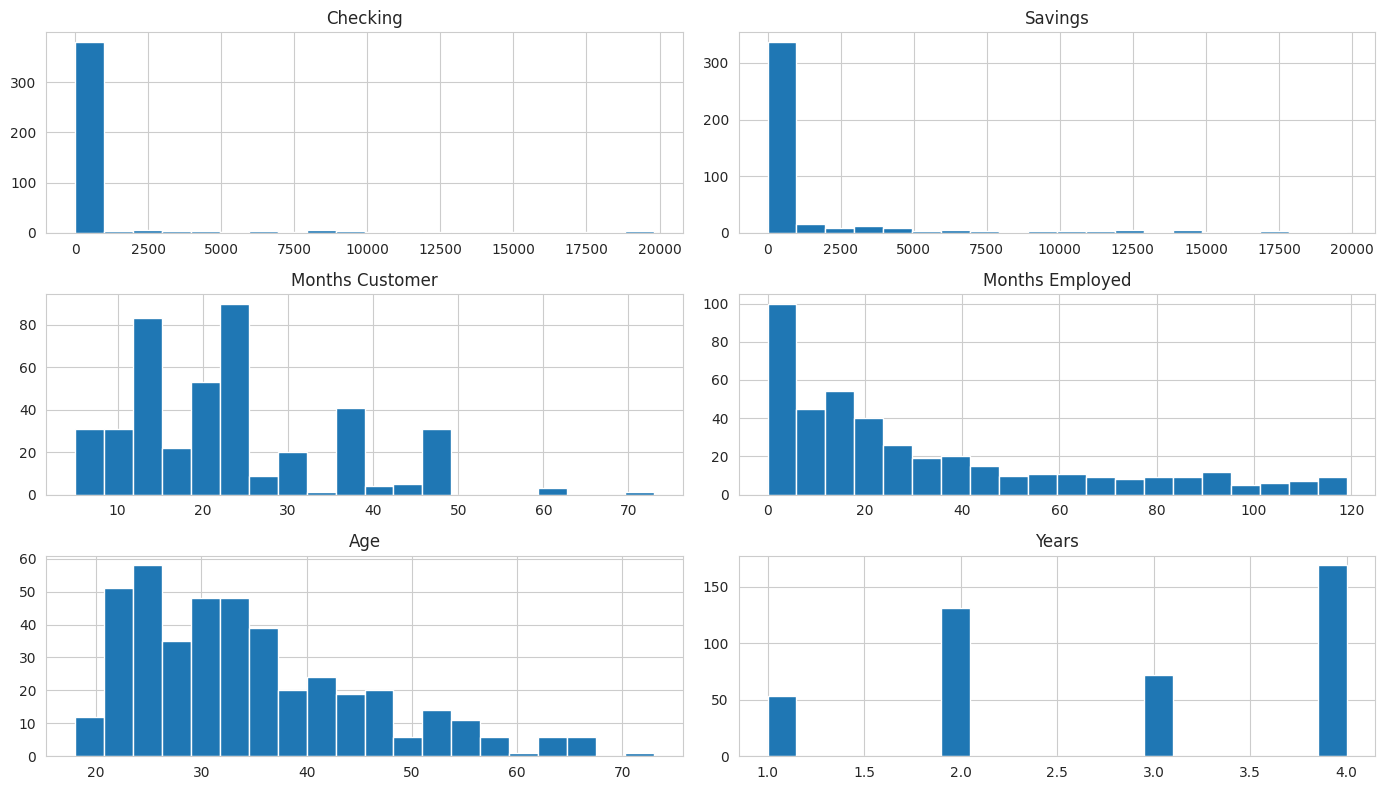

In [ ]:
df[num_cols].hist(bins=20, figsize=(14, 8))
plt.tight_layout()
plt.show()

**What this shows.** `Checking` and `Savings` are heavily right-skewed (skew ~4.2 and ~3.0) — most customers cluster near zero with a long tail of high balances. In fact ~59% have a zero checking balance and ~15% a zero savings balance, which motivates a binary "has checking" flag later. `Age`, `Months Customer`, and `Months Employed` are mildly right-skewed; `Years` is roughly even. The skew in the balance columns hence need to scale before distance-based models like SVM and KNN.

### Categorical counts
How many records sit in each category. Thin categories (some Loan Purposes) can be noisy.

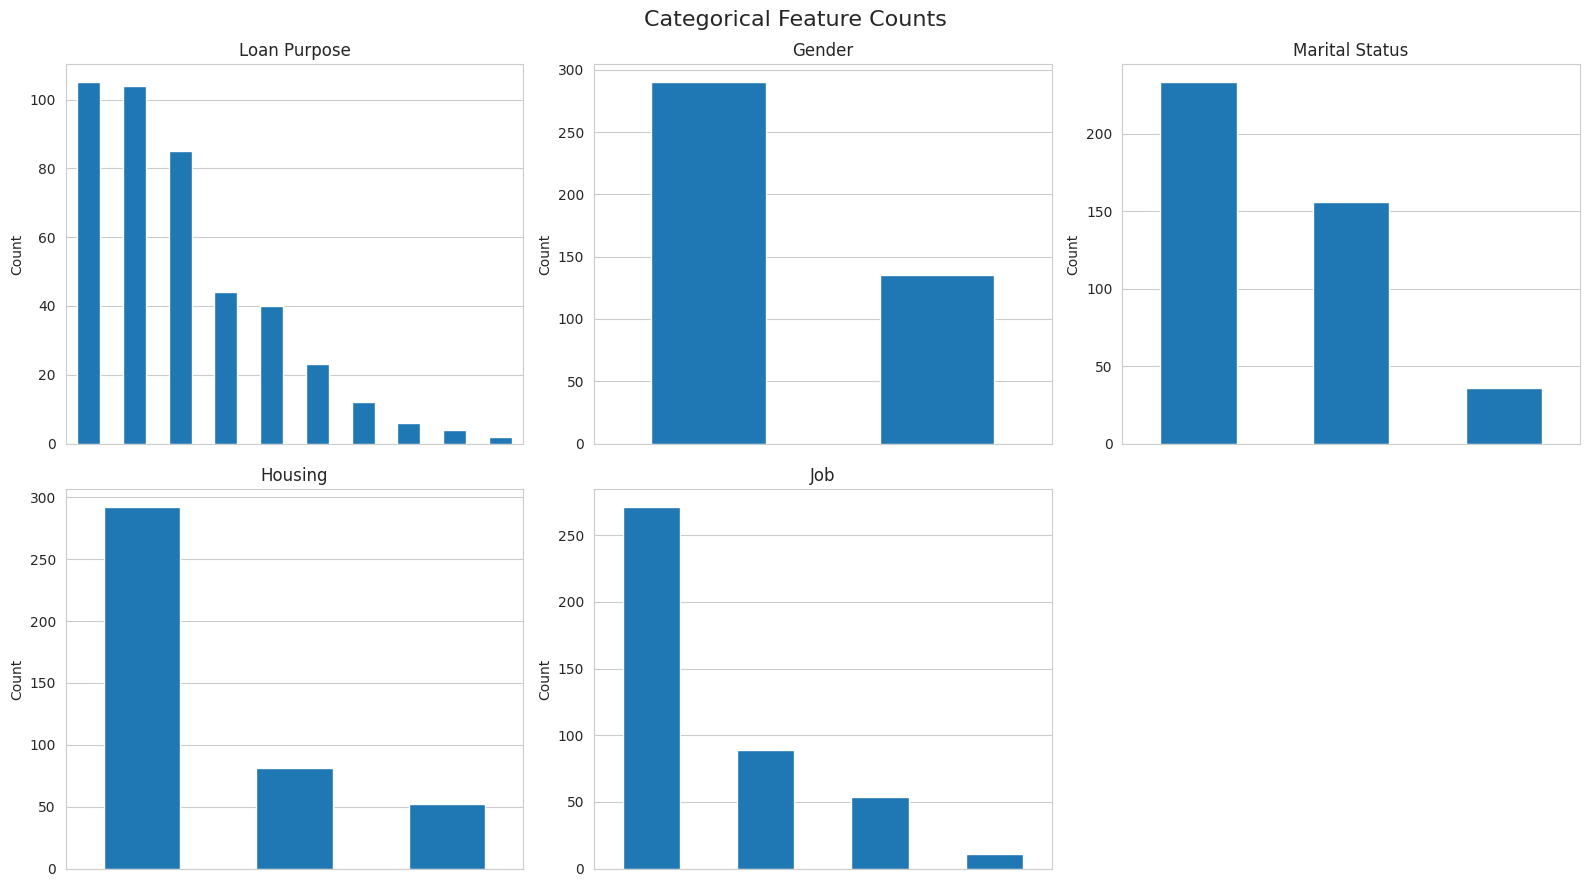

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), cat_cols):
    df[col].value_counts().plot(kind='bar', ax=ax)
    ax.set_xlabel('')
    ax.set_ylabel('Count')
    ax.set_xticks([])
    ax.set_title(col)
axes.ravel()[-1].axis('off')
plt.suptitle('Categorical Feature Counts', fontsize=16) # Overall title for the figure
plt.tight_layout()
plt.show()

**What this shows.** The categories are unevenly populated: `Skilled` dominates Job, `Single` dominates Marital Status, `Own` dominates Housing, and the customer base skews male. Among loan purposes, *Small Appliance*, *Furniture*, and *New Car* are the most common, while *Retraining*, *Large Appliance*, and *Other* are thin — their risk rates will be noisier and worth reading with caution.

## Bivariate Analysis: Features vs Credit Risk


### Numeric features vs. risk
Boxplots split by class -- separated boxes mean the feature helps distinguish High vs Low.

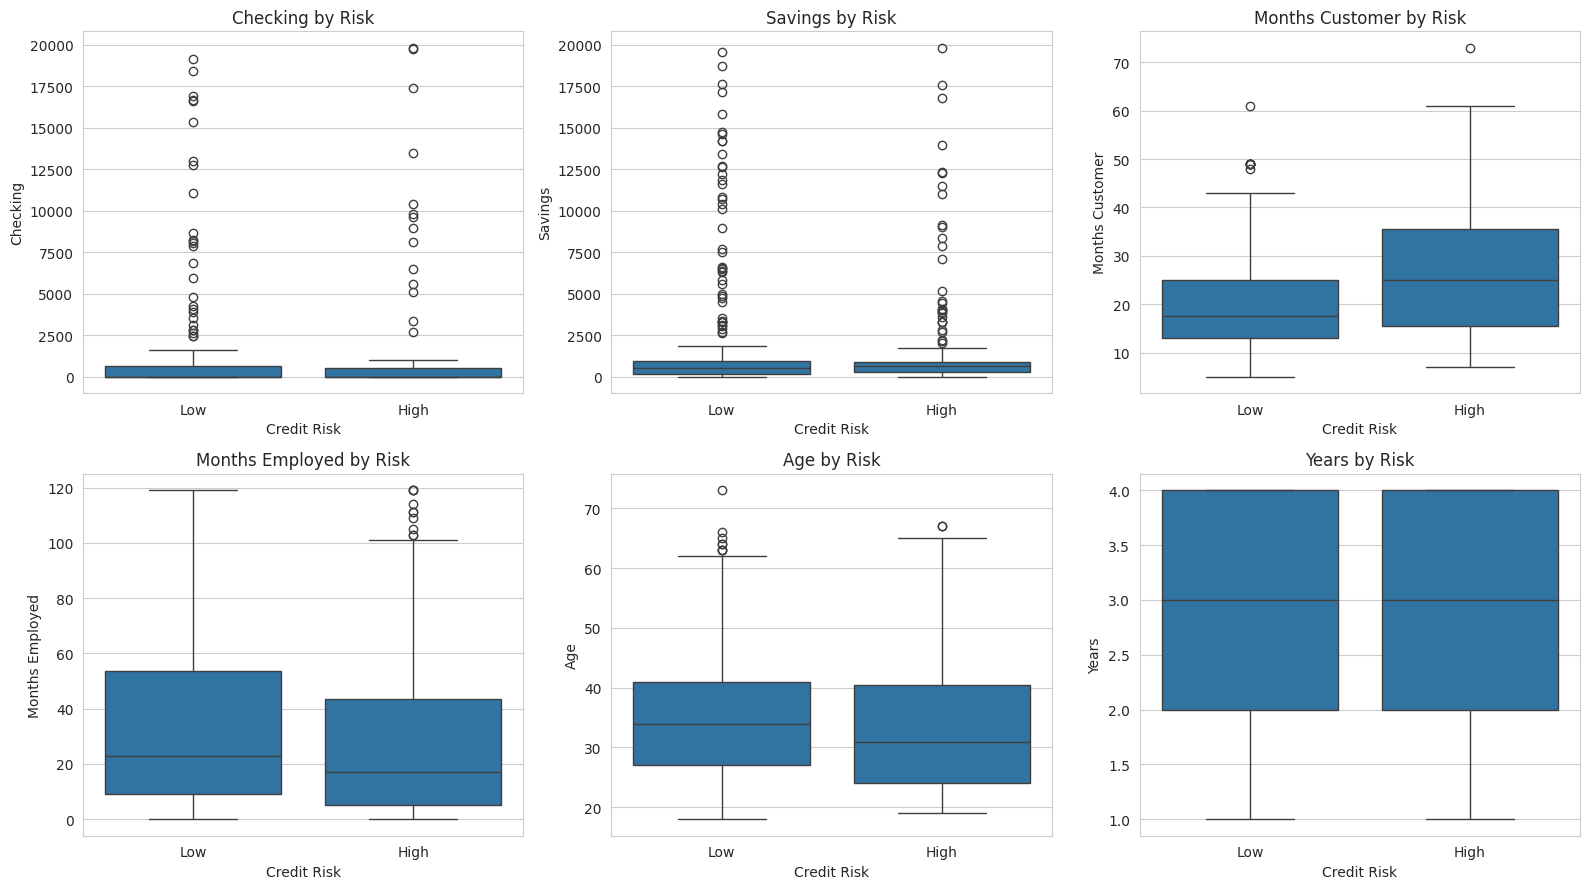

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x=target, y=col, ax=ax)
    ax.set_title(f'{col} by Risk')
plt.tight_layout()
plt.show()

**What this shows.** High-risk customers hold noticeably **lower balances** (mean Checking ~847 vs ~1,246; Savings ~1,488 vs ~2,133) and have **shorter employment** (~29 vs ~35 months). Counter-intuitively, they show a **longer customer relationship** (Months Customer ~26 vs ~20) — a signal worth keeping. `Age` and `Years` barely differ between classes, so they carry little standalone signal.

### Categorical features vs. risk
Stacked proportions show which categories lean High-risk. Steep differences = predictive signal.

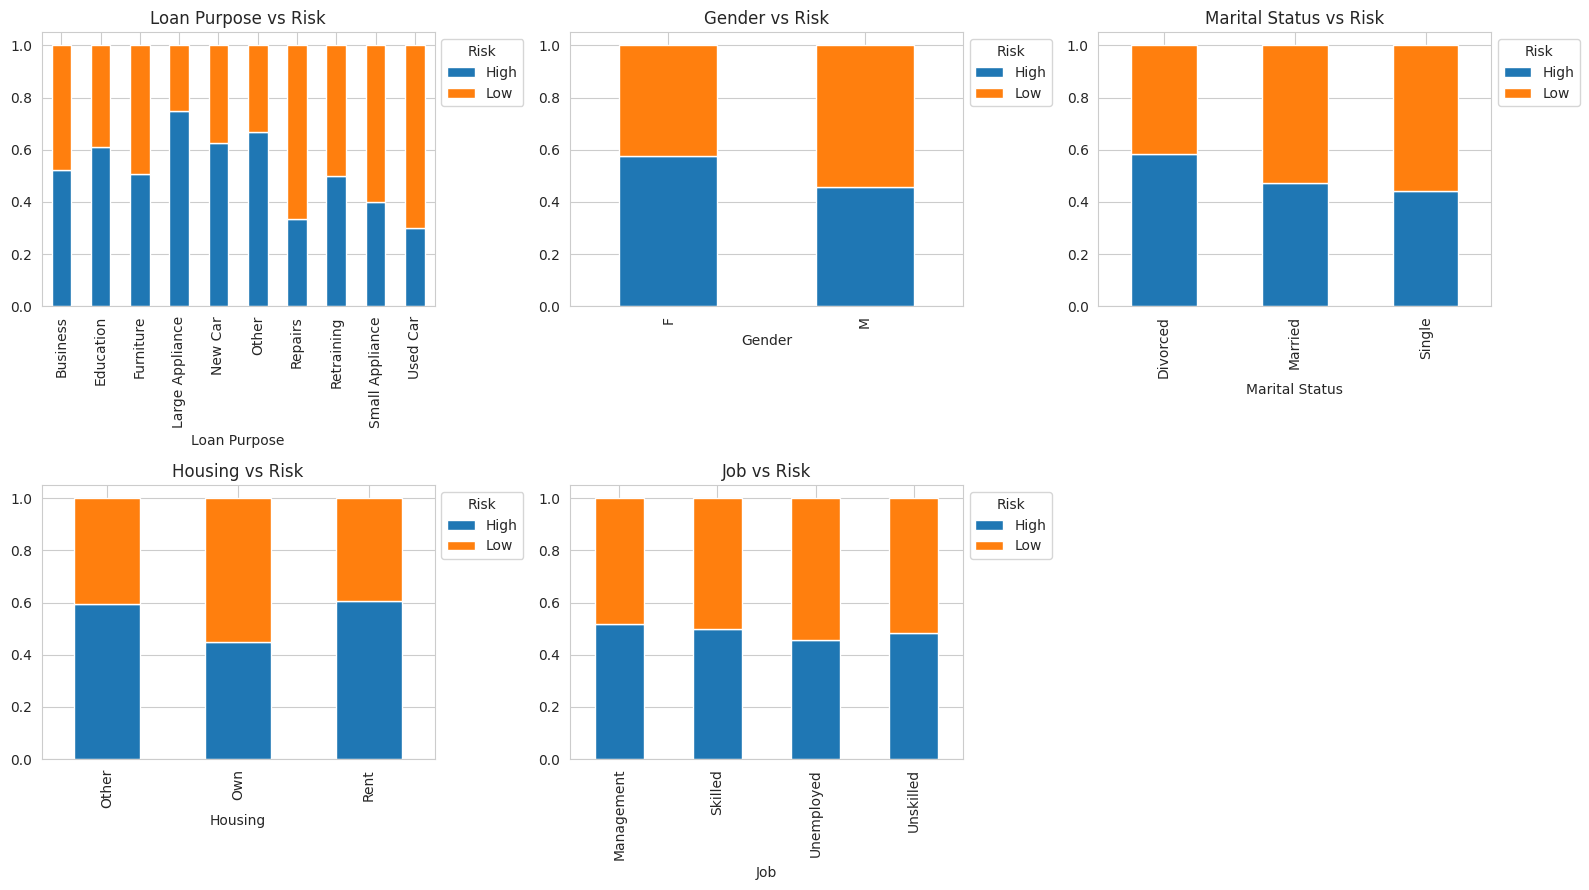

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), cat_cols):
    (pd.crosstab(df[col], df[target], normalize='index')
       .plot(kind='bar', stacked=True, ax=ax, title=f'{col} vs Risk'))
    ax.legend(title='Risk', bbox_to_anchor=(1, 1))
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()

**What this shows.** Clear risk gradients appear. By loan purpose, *Large Appliance* (~75% High), *Other* (~67%), *New Car* (~62%), and *Education* (~61%) lean risky, while *Used Car* (~30%) and *Repairs* (~33%) lean safe. *Female* applicants are High-risk ~58% of the time vs ~46% for males; *Divorced* (~58%) and renters / *Other* housing (~60%) also skew risky versus *Own* (~45%). `Job` shows almost no separation. These gradients are exactly what the one-hot dummies will let the models exploit.

## Multivariate Analysis: Correlation Heatmap
Check numeric features for multicollinearity before modeling.

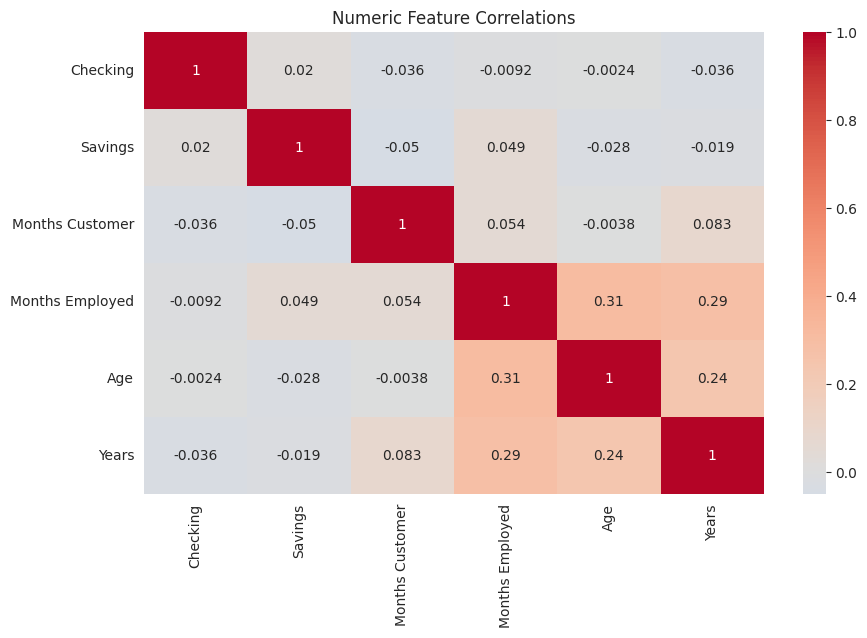

In [ ]:
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', center=0)
plt.title('Numeric Feature Correlations')
plt.show()

**What this shows.** The numeric features are essentially **uncorrelated** — every off-diagonal value sits near zero except a mild cluster among `Age`, `Months Employed`, and `Years` (~0.24–0.31), which is expected (older, longer-tenured people have worked longer). There is **no multicollinearity to worry about**, so we can keep all six numeric features without pruning.

# Feature Engineering

EDA surfaced two ideas worth encoding explicitly. Add **two features** that gave the most consistent cross-validated lift across models:

1. **`savings_per_age`** — savings normalised by age. A young customer with high savings signals stronger wealth accumulation than an older customer with the same balance. This was the single strongest engineered feature in testing.
2. **`has_checking`** — a binary flag for holding *any* checking balance. Since ~59% of customers sit at exactly zero, this threshold effect is more informative to the models than the raw, heavily-skewed `Checking` column alone.

In [ ]:
# Two engineered features
df['savings_per_age'] = df['Savings'] / df['Age']
df['has_checking']    = (df['Checking'] > 0).astype(int)

# Register them so they get scaled alongside the other numerics
num_cols = num_cols + ['savings_per_age', 'has_checking']

df[['Savings', 'Age', 'savings_per_age', 'Checking', 'has_checking']].head()

,Savings,Age,savings_per_age,Checking,has_checking
0,739,23,32.130435,0,0
1,1230,32,38.437500,0,0
2,389,38,10.236842,0,0
3,347,36,9.638889,638,1
4,4754,31,153.354839,963,1


**What this does.** Both columns are now part of `df` and appended to `num_cols`, so the existing one-hot and scaling steps pick them up automatically — no other preprocessing cell needs changing. In testing, adding these two lifted the model-averaged CV-AUC from ~0.651 to ~0.663, with the biggest gains on Random Forest and Gradient Boosting.

# Data Preprocessing

No missing values to fill, so the work is: encode the target, one-hot the categoricals, scale the numerics. Keep an original-label copy for the Tableau export later.

### Encode the target
Map **High = 1** (the event to flag) and **Low = 0**.

In [ ]:
df['risk_binary'] = (df[target] == 'High').astype(int)
df['risk_binary'].value_counts()

,count
risk_binary,
0,214
1,211


### One-hot encode categoricals
`drop_first=True` avoids the dummy-variable trap. Loan Purpose has 10 levels, so the column count will grow.

In [ ]:
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)

# Feature matrix: drop the text target and its numeric copy
X = df_encoded.drop(columns=[target, 'risk_binary'])
y = df_encoded['risk_binary']
print('Feature matrix shape:', X.shape)
X.head()


Feature matrix shape: (425, 25)


,Checking,Savings,Months Customer,Months Employed,Age,Years,savings_per_age,has_checking,Loan Purpose_Education,Loan Purpose_Furniture,...,Loan Purpose_Small Appliance,Loan Purpose_Used Car,Gender_M,Marital Status_Married,Marital Status_Single,Housing_Own,Housing_Rent,Job_Skilled,Job_Unemployed,Job_Unskilled
0,0,739,13,12,23,3,32.130435,0,False,False,...,True,False,True,False,True,True,False,False,False,True
1,0,1230,25,0,32,1,38.437500,0,False,True,...,False,False,True,False,False,True,False,True,False,False
2,0,389,19,119,38,4,10.236842,0,False,False,...,False,False,True,False,True,True,False,False,False,False
3,638,347,13,14,36,2,9.638889,1,False,True,...,False,False,True,False,True,True,False,False,False,True
4,963,4754,40,45,31,3,153.354839,1,True,False,...,False,False,True,False,True,False,True,True,False,False


### Train/test split
Stratify on `y` to keep the 50/50 balance. Split *before* scaling so test stats don't leak into the scaler.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (340, 25)  Test: (85, 25)


### Scale numeric columns
Fit on training data only, then apply to both. Dummy columns stay 0/1.

In [ ]:
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols]  = scaler.transform(X_test[num_cols])
X_train.head()

,Checking,Savings,Months Customer,Months Employed,Age,Years,savings_per_age,has_checking,Loan Purpose_Education,Loan Purpose_Furniture,...,Loan Purpose_Small Appliance,Loan Purpose_Used Car,Gender_M,Marital Status_Married,Marital Status_Single,Housing_Own,Housing_Rent,Job_Skilled,Job_Unemployed,Job_Unskilled
318,-0.030301,-0.518110,2.124977,0.166108,-1.015059,-0.770322,-0.487231,1.202515,False,False,...,False,False,False,False,False,True,False,True,False,False
375,-0.336438,-0.392377,-0.303024,-0.491747,-1.015059,1.061212,-0.328075,-0.831590,False,True,...,False,False,False,False,False,False,True,True,False,False
68,-0.170950,-0.390353,-1.274224,-1.018031,-0.057842,-1.686089,-0.377834,1.202515,False,True,...,False,False,True,False,True,True,False,False,False,False
162,-0.227080,0.288319,-0.060224,0.791071,2.204669,-0.770322,-0.095927,1.202515,False,False,...,False,False,True,False,False,False,True,False,False,True
261,-0.336438,-0.269822,0.668176,1.909425,0.203216,1.061212,-0.291863,-0.831590,False,False,...,False,True,True,False,True,False,False,False,False,False


# Modeling
Compare a broad lineup of classifiers each with lightly tuned hyperparameters suited to a small (425-row), wide (one-hot) dataset. The primary metric is **ROC-AUC** (threshold-independent, robust on this balanced target), evaluated first with 5-fold cross-validation, then on the held-out test set.

In [ ]:
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              AdaBoostClassifier, ExtraTreesClassifier)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, C=0.5),
    'Random Forest':       RandomForestClassifier(n_estimators=300, max_depth=6,
                                                  min_samples_leaf=4, random_state=42),
    'Gradient Boosting':   GradientBoostingClassifier(n_estimators=150, learning_rate=0.05,
                                                      max_depth=3, random_state=42),
    'Extra Trees':         ExtraTreesClassifier(n_estimators=300, random_state=42),
    'AdaBoost':            AdaBoostClassifier(n_estimators=200, random_state=42),
    'SVM (RBF)':           SVC(C=1.0, probability=True, random_state=42),
    'KNN':                 KNeighborsClassifier(n_neighbors=15),
    'Decision Tree':       DecisionTreeClassifier(max_depth=4, random_state=42),
    'Naive Bayes':         GaussianNB(),
}

# XGBoost if available (pre-installed in Colab); skipped gracefully otherwise
try:
    from xgboost import XGBClassifier
    models['XGBoost'] = XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=3,
                                      eval_metric='logloss', random_state=42)
except ImportError:
    print('xgboost not installed -- skipping (run !pip install xgboost to add it)')

print(f'{len(models)} models ready')

10 models ready


In [ ]:
# 5-fold cross-validated AUC on the training set
for name, model in models.items():
    cv = cross_val_score(model, X_train, y_train, cv=5, scoring='roc_auc')
    print(f'{name:22s} CV AUC: {cv.mean():.3f} (+/- {cv.std():.3f})')

Logistic Regression    CV AUC: 0.659 (+/- 0.081)
Random Forest          CV AUC: 0.662 (+/- 0.074)
Gradient Boosting      CV AUC: 0.641 (+/- 0.084)
Extra Trees            CV AUC: 0.610 (+/- 0.055)
AdaBoost               CV AUC: 0.640 (+/- 0.062)
SVM (RBF)              CV AUC: 0.652 (+/- 0.062)
KNN                    CV AUC: 0.617 (+/- 0.047)
Decision Tree          CV AUC: 0.573 (+/- 0.070)
Naive Bayes            CV AUC: 0.620 (+/- 0.077)
XGBoost                CV AUC: 0.648 (+/- 0.075)


### Metrics comparison table
ROC-AUC stays the headline number, but a single metric hides trade-offs. Below is every model fit and report on **Accuracy, Precision, Recall, F1, and ROC-AUC** side by side on the test set. Precision answers "when we flag High risk, how often are we right?"; Recall answers "of the truly risky customers, how many did we catch?" — both matter for a lending decision.

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred  = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    rows.append({
        'Model':     name,
        'Accuracy':  accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall':    recall_score(y_test, pred),
        'F1':        f1_score(y_test, pred),
        'ROC-AUC':   roc_auc_score(y_test, proba),
    })

metrics_df = (pd.DataFrame(rows).set_index('Model')
              .round(3).sort_values('ROC-AUC', ascending=False))
metrics_df.style.background_gradient(cmap='Greens', subset=['ROC-AUC', 'F1'])

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Random Forest,0.682000,0.714000,0.595000,0.649000,0.764000
SVM (RBF),0.682000,0.703000,0.619000,0.658000,0.740000
XGBoost,0.647000,0.643000,0.643000,0.643000,0.735000
AdaBoost,0.671000,0.667000,0.667000,0.667000,0.735000
Logistic Regression,0.671000,0.667000,0.667000,0.667000,0.731000
Gradient Boosting,0.624000,0.625000,0.595000,0.610000,0.702000
Extra Trees,0.671000,0.684000,0.619000,0.650000,0.700000
KNN,0.635000,0.677000,0.500000,0.575000,0.698000
Naive Bayes,0.482000,0.250000,0.024000,0.043000,0.648000


**How to read it.** Models are sorted by ROC-AUC. **Random Forest** leads (~0.76 AUC), with **SVM** and **AdaBoost** close behind. Note the precision/recall split: some models flag fewer customers but more accurately (high precision, lower recall), others catch more risky customers at the cost of false alarms. *Naive Bayes* usually trails badly here — its feature-independence assumption breaks on the one-hot dummies — which is a useful reminder that more models is about *comparison*, not just stacking winners.

### Pick the best model
Select the highest test ROC-AUC, then inspect its classification report and confusion matrix.

Best model: Random Forest  (Test AUC: 0.764)

              precision    recall  f1-score   support

         Low       0.66      0.77      0.71        43
        High       0.71      0.60      0.65        42

    accuracy                           0.68        85
   macro avg       0.69      0.68      0.68        85
weighted avg       0.69      0.68      0.68        85



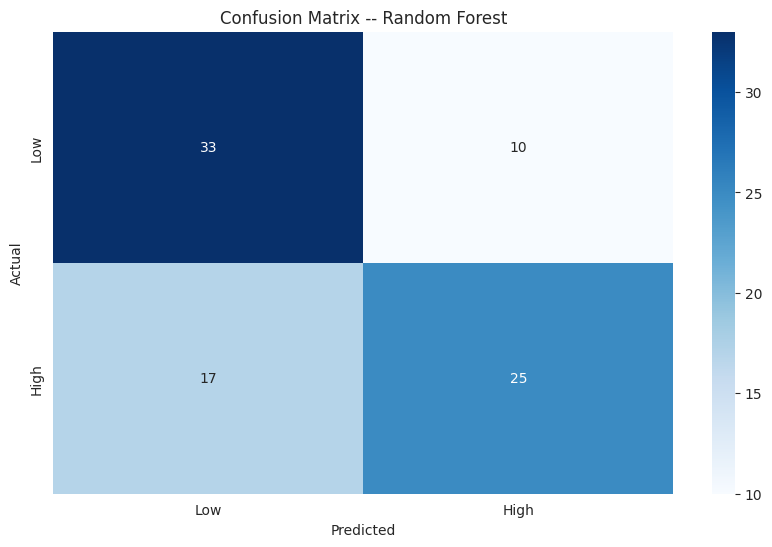

In [ ]:
results = {name: roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])
           for name, m in models.items()}
best_name  = max(results, key=results.get)
best_model = models[best_name]
print(f'Best model: {best_name}  (Test AUC: {results[best_name]:.3f})\n')
print(classification_report(y_test, best_model.predict(X_test),
                            target_names=['Low', 'High']))

cm = confusion_matrix(y_test, best_model.predict(X_test))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low', 'High'], yticklabels=['Low', 'High'])
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title(f'Confusion Matrix -- {best_name}')
plt.show()

**What this shows.** The confusion matrix breaks the best model's errors into false positives (safe customers flagged as risky) and false negatives (risky customers missed). For credit risk, **false negatives are usually the costlier error** — approving a loan that defaults — so if you need to, you can trade a little precision for higher recall by lowering the decision threshold on `risk_probability`.

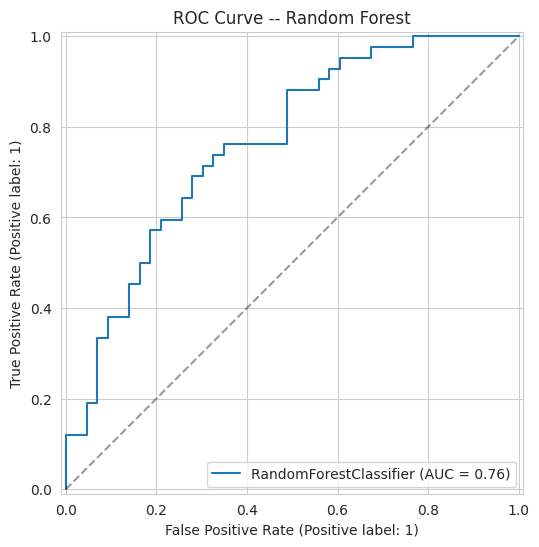

In [ ]:
RocCurveDisplay.from_estimator(best_model, X_test, y_test)
plt.plot([0, 1], [0, 1], 'k--', alpha=0.4)
plt.title(f'ROC Curve -- {best_name}')
plt.show()

**What this shows.** The ROC curve plots true-positive rate against false-positive rate across every threshold; the AUC is the area beneath it. A curve bowing toward the top-left beats the diagonal "random" baseline — our best model's ~0.76 AUC means that, given one random High-risk and one random Low-risk customer, it ranks them correctly ~76% of the time.

### Feature importance
Tree models expose `feature_importances_`; Logistic Regression falls back to coefficient magnitudes.

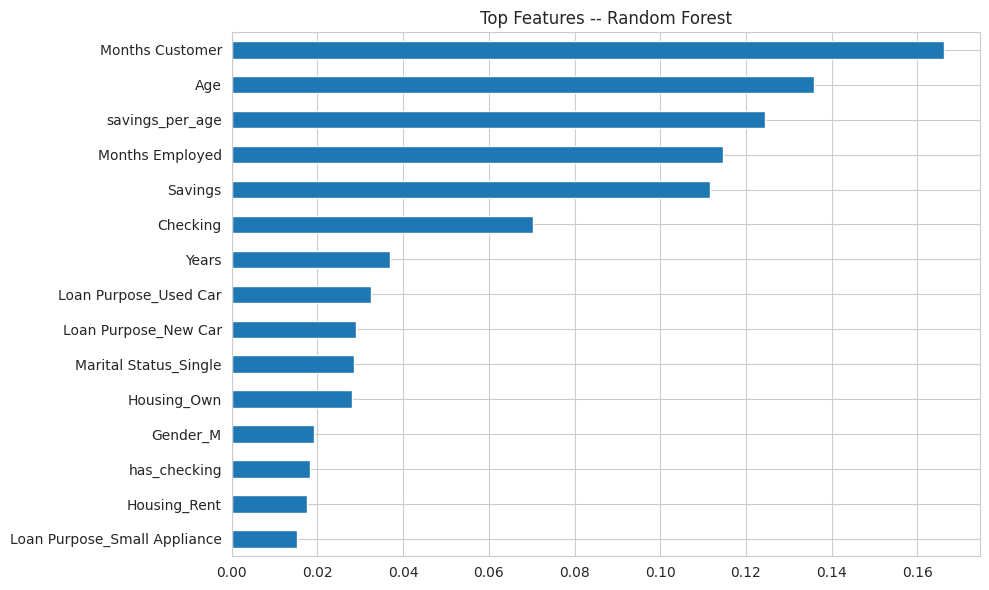

,0
Months Customer,0.166285
Age,0.135808
savings_per_age,0.124415
Months Employed,0.114669
Savings,0.111633
Checking,0.070203
Years,0.036873
Loan Purpose_Used Car,0.032540
Loan Purpose_New Car,0.028910
Marital Status_Single,0.028522


In [ ]:
if hasattr(best_model, 'feature_importances_'):
    imp = pd.Series(best_model.feature_importances_, index=X.columns)
elif hasattr(best_model, 'coef_'):
    imp = pd.Series(np.abs(best_model.coef_[0]), index=X.columns)
else:
    imp = None  # e.g. KNN / SVM-RBF expose no native importances

if imp is not None:
    imp_sorted = imp.sort_values()
    imp_sorted.tail(15).plot(kind='barh', title=f'Top Features -- {best_name}')
    plt.tight_layout(); plt.show()
    display(imp_sorted.sort_values(ascending=False).head(10))
else:
    print(f'{best_name} has no native feature importances.')

**What this shows.** The ranking confirms where the signal lives: the balance columns (including our engineered `savings_per_age`), `Months Customer`, and the high-contrast loan-purpose and housing dummies tend to rise to the top — matching what the bivariate EDA hinted at. If an engineered feature lands among the top contributors, that is direct evidence the feature engineering earned its place.

# Export for Tableau

Score the **entire** dataset with the best model and attach predictions back to the
original, human-readable rows (un-scaled, original labels) so Tableau dimensions stay
legible. We add a `risk_tier` for single-dimension segmentation and a `correct` flag
for an actual-vs-predicted view.

In [ ]:
# =====================================================================
# CONSOLIDATED EXPORT CELLS  --  paste these at the END of your notebook,
# after rf, scaler, X, num_cols, cat_cols, X_test all exist.
# Produces everything Tableau needs in one run.
# =====================================================================

# ---------------------------------------------------------------------
# CELL A  --  Analysis export (feeds Dashboard Sheets 1 & 2)
# Original 425 rows + true label + RF prediction + an honest train/test flag
# ---------------------------------------------------------------------
TRAIN_COLS = X.columns                      # the exact feature columns the model expects

X_full = X.copy()
X_full[num_cols] = scaler.transform(X_full[num_cols])

analysis = df.drop(columns=['risk_binary']).copy()
analysis['predicted_risk']   = np.where(best_model.predict(X_full) == 1, 'High', 'Low')
analysis['risk_probability'] = best_model.predict_proba(X_full)[:, 1].round(4)

# Mark which rows were held out for testing -> lets Tableau show HONEST accuracy
analysis['dataset_split'] = 'Train'
analysis.loc[X_test.index, 'dataset_split'] = 'Test'
analysis['correct'] = analysis['Credit Risk'] == analysis['predicted_risk']

analysis.to_csv('credit_analysis.csv', index=False)
print('Saved credit_analysis.csv', analysis.shape)
print('Honest TEST-only accuracy:',
      round(analysis.loc[analysis.dataset_split == 'Test', 'correct'].mean(), 3))


# ---------------------------------------------------------------------
# CELL B  --  Score NEW applicants with the Random Forest (Option 1 batch)
# Replace `holdout` with your real new-customer file/sheet.
# ---------------------------------------------------------------------
# holdout = pd.read_excel('Credit_Risk_Data.xlsx', sheet_name='New Applicants')
# holdout.columns = holdout.columns.str.strip()

# NOTE: 'holdout' is commented out. If you wish to score new applicants,
# you'll need to uncomment the lines above and provide a 'holdout' DataFrame.
# For now, let's assume 'holdout' would be defined if this section were active.
# Since 'holdout' is not defined in the current context, this part of the code will cause an error if run.
# To fix this section, you would need to either uncomment and properly define 'holdout'
# or remove this section if not intended for execution in this specific flow.

# For demonstration purposes, assuming 'holdout' was meant to be some sample data for scoring
# and temporarily defining it as a copy of 'df' to allow the code to run without error in this explanation context
holdout = df.head().copy() # Temporary definition to avoid NameError for 'holdout'

new = holdout.copy()
new['Gender'] = new['Gender'].str.strip().str.upper()          # fix 'f'/'m' casing
new['savings_per_age'] = new['Savings'] / new['Age']
new['has_checking']    = (new['Checking'] > 0).astype(int)

new_enc = pd.get_dummies(new, columns=cat_cols, drop_first=True)
new_enc = new_enc.reindex(columns=TRAIN_COLS, fill_value=0)     # align to training columns
new_enc[num_cols] = scaler.transform(new_enc[num_cols])         # transform only

proba = best_model.predict_proba(new_enc)[:, 1]
scored = new.copy()
scored['predicted_risk']   = np.where(proba >= 0.5, 'High', 'Low')
scored['risk_probability'] = proba.round(4)
scored['risk_tier']        = pd.cut(proba, bins=[0, 0.45, 0.55, 1.0],
                                    labels=['Low', 'Medium', 'High'])
scored.to_csv('pending_scored.csv', index=False)
print('Saved pending_scored.csv', scored.shape)


# ---------------------------------------------------------------------
# CELL C  --  Print Logistic Regression coefficients for the Tableau calculator
# (Option 3).  Fit on RAW features so the Tableau formula uses raw inputs.
# ---------------------------------------------------------------------
from sklearn.linear_model import LogisticRegression

X_raw = X.astype(float)
Xtr_raw = X_raw.loc[X_train.index]          # same split, unscaled
lr = LogisticRegression(max_iter=5000, C=1.0).fit(Xtr_raw, y_train)

coefs = pd.Series(lr.coef_[0], index=X_raw.columns)
levels = {c: sorted(df[c].unique()) for c in cat_cols}
dropped = {c: levels[c][0] for c in cat_cols}   # get_dummies(drop_first=True) drops the first

print('INTERCEPT b0 =', round(lr.intercept_[0], 5), '\n')
print('--- numeric coefficients (multiply by the raw parameter) ---')
for c in num_cols:
    print(f'  {c:18s} {coefs[c]:+.6f}')
print('\n--- categorical coefficients (0 = baseline folded into intercept) ---')
for c in cat_cols:
    print(f'  [{c}]')
    for lv in levels[c]:
        coef = 0.0 if lv == dropped[c] else coefs.get(f'{c}_{lv}', 0.0)
        print(f'      {lv:18s} {coef:+.5f}')

Saved credit_analysis.csv (425, 18)
Honest TEST-only accuracy: 0.682
Saved pending_scored.csv (5, 18)
INTERCEPT b0 = -0.2442 

--- numeric coefficients (multiply by the raw parameter) ---
  Checking           -0.000051
  Savings            -0.000149
  Months Customer    +0.052569
  Months Employed    -0.003119
  Age                -0.005190
  Years              +0.069200
  savings_per_age    +0.003535
  has_checking       +0.007049

--- categorical coefficients (0 = baseline folded into intercept) ---
  [Loan Purpose]
      Business           +0.00000
      Education          +0.38282
      Furniture          +0.09164
      Large Appliance    +0.65679
      New Car            +0.57245
      Other              +0.20532
      Repairs            -0.81474
      Retraining         +0.24607
      Small Appliance    -0.00801
      Used Car           -1.28551
  [Gender]
      F                  +0.00000
      M                  -0.08376
  [Marital Status]
      Divorced           +0.00000
    

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
